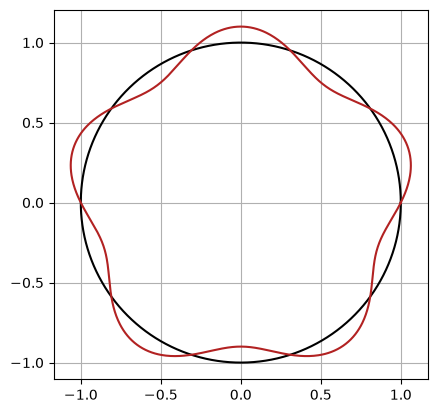

In [23]:
import numpy as np
import matplotlib.pyplot as plt

r = 1
A = 0.1

# 6 wavelengths around the circumference
k = 5 / r

t = 0
omega = 1
phi = 0

theta = np.linspace(0, 2*np.pi, 1000)

# Circle
x_circle = r * np.cos(theta)
y_circle = r * np.sin(theta)

# Wave
rho = r + A * np.sin(k*r*theta - omega*t + phi)

x_wave = rho * np.cos(theta)
y_wave = rho * np.sin(theta)

fig, ax = plt.subplots()

ax.plot(x_circle, y_circle, 'k')
ax.plot(x_wave, y_wave, 'firebrick')

ax.set_aspect('equal')
ax.grid()

plt.savefig("wavelength5")
plt.show()

R = 1.10453e+07 m^-1


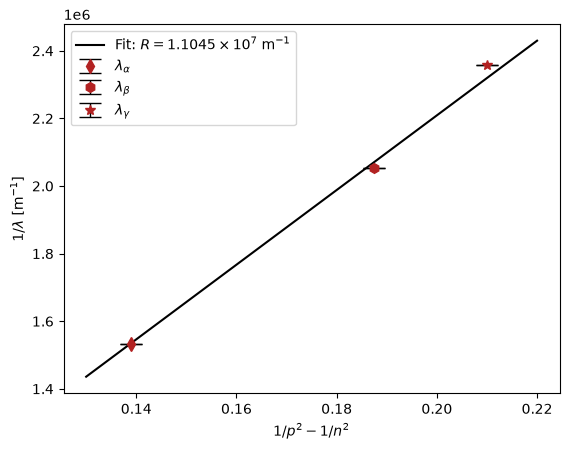

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Data (alpha, beta, gamma)
n = np.array([3, 4, 5])
lam = np.array([653.006, 487.016, 424.296]) * 1e-9        # m
dlam = np.array([2.397e-4, 2.398e-4, 2.398e-4]) * 1e-9    # m

p = 2
x = 1 / p**2 - 1 / n**2
y = 1 / lam
dy = dlam / lam**2          # propagated error on 1/lambda

# Fit 1/lambda = R * x
def model(x, R):
    return R * x

popt, pcov = curve_fit(model, x, y, p0=[1.1e7], sigma=dy, absolute_sigma=False)
R = popt[0]
print(f"R = {R:.5e} m^-1")

fig, ax = plt.subplots()

# One marker and label per Balmer line
markers = ['d', 'h', '*']   # diamond, square, triangle
labels  = [r'$\lambda_\alpha$', r'$\lambda_\beta$', r'$\lambda_\gamma$']

for xi, yi, dyi, m, lab in zip(x, y, dy, markers, labels):
    ax.errorbar(xi, yi, yerr=dyi, fmt=m, capsize=8,
                color='firebrick', ecolor='black',
                elinewidth=1, capthick=1,
                markersize=7,
                label=lab)


# Fit line
xx = np.linspace(0.13, 0.22, 100)
ax.plot(xx, model(xx, R), color='black', linewidth=1.5,
        label=rf'Fit: $R = {R/1e7:.4f} \times10^7$ m$^{{-1}}$')

ax.set_xlabel(r'$1/p^2 - 1/n^2$')
ax.set_ylabel(r'$1/\lambda$ [m$^{-1}$]')
ax.legend()
plt.savefig("fit")
plt.show()

23.420929908752434 -0.02408719807863177 65.1096270861619 15.601093201762152


C:\Users\nhoco\AppData\Local\Temp\ipykernel_12764\3936495346.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "g^" (-> color='g'). The keyword argument will take precedence.
  plt.plot(x[:-1], y[:-1], 'g^', color='firebrick')


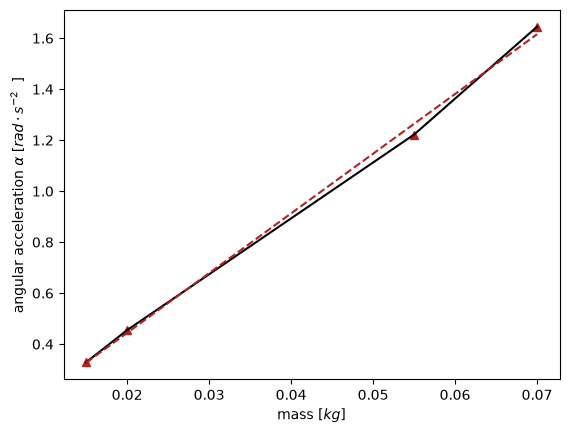

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

data = np.array([(15, 0.329), (20, 0.455), (55, 1.222), (70, 1.645), (120, 7.522)],
               dtype=[('mass', 'i4'), ('accel', 'f4')])

x = data['mass'] / 1000
y = data['accel']


slope, intercept = np.polyfit(x[:-1], y[:-1], 1)

slope_line = slope * x + intercept

res = linregress(x, y)
k, dk = res.slope, res.stderr

#plt.plot(x, y, 'g^', color='firebrick')
#plt.plot(x, y, color='black')
#plt.plot(x, slope_line, '--', color='firebrick')
#plt.xlabel(r'mass [$kg$]')
#plt.ylabel(r'angular acceleration $\alpha$ [$rad\cdot s^{-2}$  ]')

#plt.savefig("gyroscope_1")

plt.plot(x[:-1], y[:-1], 'g^', color='firebrick')
plt.plot(x[:-1], y[:-1], color='black')
plt.plot(x[:-1], slope_line[:-1], '--', color='firebrick')
plt.xlabel(r'mass [$kg$]')
plt.ylabel(r'angular acceleration $\alpha$ [$rad\cdot s^{-2}$  ]')

plt.savefig("gyroscope_2")

print(slope, intercept, k ,dk)

[0.01  0.015 0.025 0.03  0.04  0.05  0.07  0.115 0.15  0.16 ]


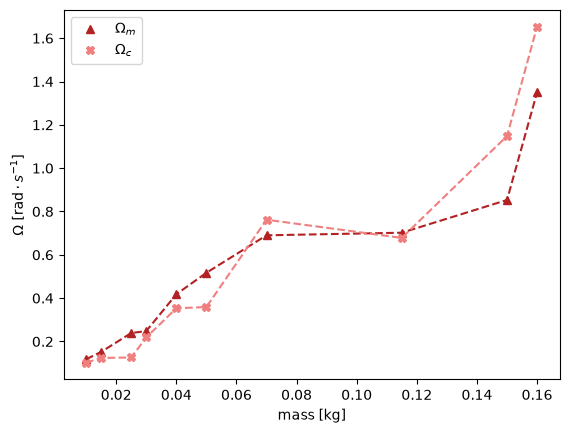

In [86]:
import numpy as np
import matplotlib.pyplot as plt

mass = np.array([0.01, 0.015, 0.025, 0.03, 0.04, 0.05, 0.07, 0.09, 0.105, 0.115, 0.125, 0.150, 0.160, 0.175])

meas = np.array([0.118, 0.152, 0.239, 0.248, 0.418, 0.517, 0.690 , 0.479 , 0.625 , 0.702,0.710 , 0.853 ,1.35,0.405  ])

calc = np.array([0.102, 0.124, 0.126, 0.219, 0.353, 0.359, 0.762, 1.086, 1.578, 0.678, 1.275,1.148, 1.653, 1.701 ])

nm = np.delete(mass, [7,8, 10, 13])
nmes = np.delete(meas, [7,8, 10, 13])
nc = np.delete(calc, [7,8, 10, 13])

print(nm)

plt.plot(nm, nmes, '^', color="firebrick")
plt.plot(nm, nc, 'X', color="lightcoral")
plt.plot(nm, nmes, '--', color="firebrick")
plt.plot(nm, nc, '--', color="lightcoral")
plt.legend([r'$\Omega_m$', r'$\Omega_c$' ])
plt.xlabel(r'mass [kg]')
plt.ylabel(r'$\Omega\,\,[\text{rad} \cdot s^{-1}]$')

plt.savefig("gyroscope_4")

In [16]:
import numpy as np
import math

omega_1 = np.array([133, 160, 199, 173, 143, 175, 124, 102, 84, 211, 125, 165, 116, 131])
omega_2 = np.array([107, 134, 285, 162, 134, 166, 111, 101, 79, 202, 116, 155, 121, 121])
omega_c = np.array([0.102, 0.124, 0.126, 0.219, 0.353, 0.359, 0.762, 1.086, 1.578, 0.678, 1.275, 1.148, 1.653, 1.701])
mass = np.array([0.01, 0.015, 0.025, 0.03, 0.04, 0.05, 0.07, 0.09, 0.105, 0.115, 0.125, 0.150, 0.160, 0.175])

del_m = 0.001
del_d = 0.0005


for x in range(0, omega_1.size):
    del_w = abs(omega_1[x] * (math.pi/30) - omega_2[x] * (math.pi/30)) / 2
    averg = (omega_1[x] * (math.pi/30) + omega_2[x] * (math.pi/30))/2

    del_omega_c = omega_c[x] * math.sqrt( pow(del_m/mass[x], 2) + pow(del_d/0.115, 2) + pow(del_w/averg, 2) + (3.665 * (pow(10, -4)/8.796*(pow(10, -3)))**2))

    print(del_omega_c)

0.01504457287422507
0.013743409220754552
0.022955249948209158
0.01029114960210264
0.01455270930474632
0.011990234697504711
0.043661958102427324
0.014018528077282884
0.05114650141005301
0.016178493502336463
0.04900891164677408
0.037020295179865326
0.03707482075733765
0.06859609370130985
